In [ ]:
# ===== COLAB SETUP + CHECKS (try 6: kd4_full) =====
# Run this cell FIRST on its own. It must end with "Setup complete" and list 4 teachers.
# Recreates Kaggle's folders so every other cell runs unchanged:
#   /content/kaggle_input (INPUT_ROOT) <- competition data, the three teachers and the stopped run's checkpoint (from the Kaggle API)
#   /kaggle/working -> Google Drive folder, so checkpoints and submissions survive a disconnect.
# Needs: Runtime -> Change runtime type -> A100 GPU, and a Kaggle API token for the account that owns
# try2-weights / try4-weights / viral_try3 / try5_viral (Colab Secrets "KAGGLE_API_TOKEN", or upload kaggle.json).
import os, sys, glob, shutil, subprocess
from google.colab import drive
drive.mount("/content/drive")

KAGGLE_USER = "viral0401"
DRIVE_RUN_DIR = "/content/drive/MyDrive/dl_project1_try6_colab"          # this run's outputs (new folder)
TRY5_FINAL = "/content/drive/MyDrive/dl_project1_try5_colab/kd3_full_ema_seed42/checkpoints/final_resnet.pth"
RUN_NAME_CHECK = "kd4_full_e200_ema_seed42"
COMPETITION = "cifar-10-res-net-architecture-challenge-dl"

def sh(command):
    """Run a shell command and SHOW its output (Colab hides subprocess output otherwise)."""
    print("$", " ".join(command))
    result = subprocess.run(command, capture_output=True, text=True)
    if result.stdout.strip():
        print(result.stdout[-2000:])
    if result.returncode != 0:
        print("ERROR OUTPUT:\n" + (result.stderr or result.stdout)[-3000:])
        raise RuntimeError(f"Command failed with exit code {result.returncode} (message above).")

# --- Kaggle credentials ---
try:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN").strip()
    print("Kaggle token: Colab secret KAGGLE_API_TOKEN")
except Exception:
    if not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
        from google.colab import files
        print("No KAGGLE_API_TOKEN secret found: upload kaggle.json")
        uploaded = files.upload()
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        shutil.move(list(uploaded)[0], os.path.expanduser("~/.kaggle/kaggle.json"))
        os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    print("Kaggle token: kaggle.json")
sh([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle", "kagglehub"])

# --- /kaggle/working -> Google Drive ---
os.makedirs(DRIVE_RUN_DIR, exist_ok=True)
os.makedirs("/kaggle", exist_ok=True)
if not os.path.islink("/kaggle/working"):
    if os.path.isdir("/kaggle/working"):
        shutil.rmtree("/kaggle/working")
    os.symlink(DRIVE_RUN_DIR, "/kaggle/working")
print("/kaggle/working ->", os.path.realpath("/kaggle/working"))

# --- INPUT_ROOT (Colab's own /kaggle/input is read-only, so inputs live here; re-downloaded per session) ---
INPUT_ROOT = "/content/kaggle_input"
os.makedirs(INPUT_ROOT, exist_ok=True)
COMP_DIR = f"{INPUT_ROOT}/competitions/{COMPETITION}"
def from_kagglehub(kind, handle):
    """Second route: kagglehub (Kaggle's official Python downloader). Returns a local folder."""
    import kagglehub
    print(f"kagglehub.{kind}({handle!r}) ...")
    return getattr(kagglehub, kind)(handle)

# Competition data: this class competition does NOT allow API downloads of its files (404), so a tiny
# CPU-only Kaggle notebook ("dataset_download") zips them into its output, which the API can download.
DATA_EXPORT_NOTEBOOK = "dataset-download"
if not os.path.isfile(f"{COMP_DIR}/train_labels.csv"):
    export_dir = "/content/comp_export"
    if not glob.glob(f"{export_dir}/**/cifar_comp_data.zip", recursive=True):
        try:
            sh(["kaggle", "kernels", "output", f"{KAGGLE_USER}/{DATA_EXPORT_NOTEBOOK}", "-p", export_dir])
        except Exception as error:
            print("Kaggle CLI route failed:", error, "\n-> trying kagglehub")
            source = from_kagglehub("notebook_output_download", f"{KAGGLE_USER}/{DATA_EXPORT_NOTEBOOK}")
            shutil.copytree(source, export_dir, dirs_exist_ok=True)
    archives = glob.glob(f"{export_dir}/**/cifar_comp_data.zip", recursive=True)
    assert archives, f"cifar_comp_data.zip not found; did the {DATA_EXPORT_NOTEBOOK} notebook finish (Save & Run All)?"
    os.makedirs(COMP_DIR, exist_ok=True)
    sh(["unzip", "-q", "-o", archives[0], "-d", COMP_DIR])
assert os.path.isfile(f"{COMP_DIR}/train_labels.csv"), "Competition data missing."
assert len(os.listdir(f"{COMP_DIR}/train_images")) == 50000 and len(os.listdir(f"{COMP_DIR}/test_images")) == 2000
print("Competition data ready:", COMP_DIR)
import zipfile
for name in ["try2-weights", "try4-weights"]:
    target = f"{INPUT_ROOT}/datasets/{KAGGLE_USER}/{name}"
    final_path = f"{target}/final_resnet.pth"
    if not os.path.isfile(final_path):
        os.makedirs(target, exist_ok=True)
        try:
            download_dir = f"/content/dl_{name}"
            sh(["kaggle", "datasets", "download", f"{KAGGLE_USER}/{name}", "-p", download_dir])
            archive = glob.glob(f"{download_dir}/*")[0]
            with zipfile.ZipFile(archive) as z:
                if "final_resnet.pth" in z.namelist():   # dataset archive that contains the checkpoint
                    z.extract("final_resnet.pth", target)
                else:                                     # the download IS the checkpoint (PyTorch files are zips)
                    shutil.copy(archive, final_path)
        except Exception as error:
            print(f"Kaggle CLI route failed for {name}:", error, "\n-> trying kagglehub")
            source = from_kagglehub("dataset_download", f"{KAGGLE_USER}/{name}")
            found = glob.glob(f"{source}/**/final_resnet.pth", recursive=True)
            assert found, f"kagglehub download of {name} has no final_resnet.pth: {source}"
            shutil.copy(found[0], final_path)
    print(name, "->", final_path, round(os.path.getsize(final_path) / 1e6, 1), "MB")
for slug in ["viral-try3"]:
    target = f"{INPUT_ROOT}/notebooks/{KAGGLE_USER}/{slug}"
    if not os.path.isdir(target) or not os.listdir(target):
        try:
            sh(["kaggle", "kernels", "output", f"{KAGGLE_USER}/{slug}", "-p", target])
        except Exception as error:
            print(f"Kaggle CLI route failed for {slug}:", error, "\n-> trying kagglehub")
            source = from_kagglehub("notebook_output_download", f"{KAGGLE_USER}/{slug}")
            shutil.copytree(source, target, dirs_exist_ok=True)
    print(slug, "->", target)

# Try 5's final model lives on Google Drive (it finished on Colab).
assert os.path.isfile(TRY5_FINAL), f"Try 5 model not found on Drive: {TRY5_FINAL}"
try5_target = f"{INPUT_ROOT}/drive/try5/final_resnet.pth"
os.makedirs(os.path.dirname(try5_target), exist_ok=True)
if not os.path.isfile(try5_target):
    shutil.copy(TRY5_FINAL, try5_target)
print("try5 ->", try5_target, round(os.path.getsize(try5_target) / 1e6, 1), "MB")

# --- checks before anything else runs ---
import torch
teachers = sorted(glob.glob(f"{INPUT_ROOT}/**/final_resnet.pth", recursive=True))
print("\nTeacher files:", *teachers, sep="\n  ")
assert len(teachers) == 4, "Expected 4 teacher final_resnet.pth files (try2, try3, try4, try5)."
print("\nTeacher checks:")
for path in teachers:
    with open(path, "rb") as handle:
        assert handle.read(2) == b"PK", f"{path} is not a valid PyTorch checkpoint (was it unpacked?)"
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    config = checkpoint["config"]
    assert config["blocks"] == [4, 4, 3] and config["channels"] == [64, 128, 256] and config["stem_channels"] == 64
    assert checkpoint["epoch"] == config["epochs"], f"{path} did not finish training"
    print(f"  OK  preset={config['preset']:<9} epoch={checkpoint['epoch']}  {path}")
    del checkpoint
own = glob.glob(f"/kaggle/working/{RUN_NAME_CHECK}/checkpoints/latest_resnet.pth")
if own:
    checkpoint = torch.load(own[0], map_location="cpu", weights_only=True)
    print(f"\nThis run already has a checkpoint on Drive: completed epochs {checkpoint['epoch']} -> it will RESUME.")
    del checkpoint
else:
    print("\nNo checkpoint for this run yet -> it will start FRESH from epoch 1.")
import psutil
print("\nRAM:", round(psutil.virtual_memory().total / 1e9, 1), "GB | CPUs:", os.cpu_count())
print("Setup complete. GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE (set an A100 or L4 runtime!)")
assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> A100 (or L4)."

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kaggle token: Colab secret KAGGLE_API_TOKEN
$ /usr/bin/python3 -m pip install -q -U kaggle kagglehub
/kaggle/working -> /content/drive/MyDrive/dl_project1_try6_colab
$ kaggle kernels output viral0401/dataset-download -p /content/comp_export

Output file downloaded to /content/comp_export/cifar_comp_data.zip
Kernel log downloaded to /content/comp_export/dataset-download.log 

$ unzip -q -o /content/comp_export/cifar_comp_data.zip -d /content/kaggle_input/competitions/cifar-10-res-net-architecture-challenge-dl
Competition data ready: /content/kaggle_input/competitions/cifar-10-res-net-architecture-challenge-dl
$ kaggle datasets download viral0401/try2-weights -p /content/dl_try2-weights
Dataset URL: https://www.kaggle.com/datasets/viral0401/try2-weights
License(s): unknown


try2-weights -> /content/kaggle_input/datasets/viral0401/try2-weights/final_resnet.pth 

In [ ]:
import torch
import torchvision
import sys

print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
          "GB")
else:
    device = torch.device("cpu")
    print("WARNING: GPU not available!")

Python version: 3.13.16
PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
GPU count: 1
GPU memory: 85.09 GB


In [ ]:
# Experiment settings. Keep this notebook private while the competition is open.
# RUN ALL from a fresh GPU session (Accelerator: "GPU T4 x2" is fastest; a single T4 also works).
# Presets: kd3_full (default), kd_full, kd_val, sla_full, sla_val, no_sla_val.
#   kd3_full   -> try 5: second-round distillation from THREE frozen teachers
#                 (try 2: Kaggle 90.9%, try 3: 90.2%, try 4 student: 91.5%), ALL 50k images, 180 epochs.
#                 REQUIRED INPUTS: Datasets -> "try2-weights", Datasets -> "try4-weights", Your Work -> "viral_try3".
#                 Do NOT attach viral_try4 (its outputs are not needed and could confuse the checkpoint search).
#   kd_full    -> try 4: distillation from two teachers (try 2 + try 3), 200 epochs.
#   kd_val     -> the same distillation on 45k images, scored on try 2's 5k validation split.
#                 Run it in parallel with kd_full to MEASURE whether distillation helps (compare with 97.88%).
#                 Caveat for the report: try 3 trained on all 50k, so it has seen these 5k images.
#   sla_full   -> try-3 recipe (no teachers), all 50k images.
#   sla_val    -> 45k train / 5k validation. Measures changes (raw vs EMA) and picks the inference mode.
#   no_sla_val -> ablation: same recipe WITHOUT rotation self-supervision (about 4x faster).
# The student is ONE ResNet with 4.71M parameters; the teachers are only used during training.
import random
import numpy as np

PRESET = "kd4_full"
RUN_NAME = PRESET + "_e200_ema_seed42"
SEED = 42
# Automatic resume: if Colab disconnected earlier, this run's checkpoint on Google Drive is picked up.
# A fresh start uses "" (no checkpoint yet). Just reconnect and Run all.
_resume_candidates = sorted(__import__("glob").glob(f"/kaggle/working/{RUN_NAME}/checkpoints/latest_resnet.pth"))
RESUME_FROM = _resume_candidates[0] if _resume_candidates else ""
SUBMIT_TO_KAGGLE = False  # Keep False: review the CSVs first, then submit manually.
PUBLIC_KAGGLE_ACCURACY_PERCENT = None  # Enter the exact public score after submission.

presets = {
    # inference_mode: "auto" = chosen on validation; sla_full has no validation, so it uses
    # "flip", the mode that won on sla_val_e200_seed42 (plain 97.88% -> flip 98.02%).
    # try 6: four teachers (try 2, 3, 4, 5), each predicting on the image AND its mirror (averaged), 200 epochs.
    "kd4_full": dict(sla=True, kd=True, teacher_count=4, teacher_flip=True, epochs=200, validation_fraction=0.0, inference_mode="flip"),
    "kd3_full": dict(sla=True, kd=True, teacher_count=3, epochs=180, validation_fraction=0.0, inference_mode="flip"),
    "kd_full": dict(sla=True, kd=True, teacher_count=2, epochs=200, validation_fraction=0.0, inference_mode="flip"),
    # kd_val: same distillation on 45k, scored on the SAME 5k holdout as try 2 (97.88% / 98.02%).
    "kd_val": dict(sla=True, kd=True, teacher_count=2, epochs=200, validation_fraction=0.10, inference_mode="auto"),
    "sla_full": dict(sla=True, kd=False, teacher_count=0, epochs=200, validation_fraction=0.0, inference_mode="flip"),
    "sla_val": dict(sla=True, kd=False, teacher_count=0, epochs=200, validation_fraction=0.10, inference_mode="auto"),
    "no_sla_val": dict(sla=False, kd=False, teacher_count=0, epochs=200, validation_fraction=0.10, inference_mode="auto"),
}
assert PRESET in presets
CONFIG = dict(presets[PRESET], preset=PRESET, seed=SEED,
    blocks=[4, 4, 3], channels=[64, 128, 256], stem_channels=64,
    batch_size=256, learning_rate=0.2, momentum=0.9, weight_decay=5e-4,
    warmup_epochs=5, minimum_lr=1e-4, label_smoothing=0.1,
    trivialaugment=True, cutout_size=12, sd_weight=1.0, plain_ce_weight=1.0,
    ema_decay=0.999, final_weights="auto",
    kd_temperature=4.0, kd_weight=1.0, loader_timeout_seconds=120,
    split_seed=42, num_workers=4)
# ema_decay 0.999 averages roughly the last 1,000 steps (about 5 epochs at batch 256).
# final_weights: "auto" = raw vs EMA chosen on validation; sla_full has no validation, so the main
# submission.csv uses the raw weights (the proven try-2 recipe) and submission_ema.csv is written too.
# Distillation: the student also matches the teachers' averaged soft predictions (temperature 4) on the
# same augmented images. kd_weight 1.0 gives the teacher term the same weight as the label term.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
# Fast cuDNN kernels. (improved_v1 used deterministic mode, which made every epoch slower.)
torch.backends.cudnn.benchmark = True
torch.backends.cudnn.deterministic = False
print("Selected experiment:", RUN_NAME)
print(CONFIG)

Selected experiment: kd4_full_e200_ema_seed42
{'sla': True, 'kd': True, 'teacher_count': 4, 'teacher_flip': True, 'epochs': 200, 'validation_fraction': 0.0, 'inference_mode': 'flip', 'preset': 'kd4_full', 'seed': 42, 'blocks': [4, 4, 3], 'channels': [64, 128, 256], 'stem_channels': 64, 'batch_size': 256, 'learning_rate': 0.2, 'momentum': 0.9, 'weight_decay': 0.0005, 'warmup_epochs': 5, 'minimum_lr': 0.0001, 'label_smoothing': 0.1, 'trivialaugment': True, 'cutout_size': 12, 'sd_weight': 1.0, 'plain_ce_weight': 1.0, 'ema_decay': 0.999, 'final_weights': 'auto', 'kd_temperature': 4.0, 'kd_weight': 1.0, 'loader_timeout_seconds': 120, 'split_seed': 42, 'num_workers': 4}


In [ ]:
# Kaggle mounts competition data directly. No credentials are required.
from pathlib import Path
DATA_DIR = Path(f"{INPUT_ROOT}/competitions/cifar-10-res-net-architecture-challenge-dl")
if not (DATA_DIR / "train_labels.csv").is_file():
    alternate = Path(f"{INPUT_ROOT}/cifar-10-res-net-architecture-challenge-dl")
    if (alternate / "train_labels.csv").is_file():
        DATA_DIR = alternate
assert (DATA_DIR / "train_labels.csv").is_file(), (
    "Attach NYU Tandon Deep Learning F26 using Add Input, then rerun."
)
print("Competition data:", DATA_DIR)

Competition data: /content/kaggle_input/competitions/cifar-10-res-net-architecture-challenge-dl


In [ ]:
# Verify mounted files without recursively scanning 52,000 images.
for name in ["train_images", "test_images", "train_labels.csv", "test.csv", "sample_submission.csv"]:
    path = DATA_DIR / name
    assert path.exists(), f"Missing competition input: {path}"
    print(name, "ready")

train_images ready
test_images ready
train_labels.csv ready
test.csv ready
sample_submission.csv ready


In [ ]:
# All writable artifacts go to Kaggle working storage.
import json
import hashlib
OUTPUT_DIR = Path("/kaggle/working") / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR = OUTPUT_DIR  # Preserve the original notebook's variable name.
CONFIG_SIGNATURE = hashlib.sha256(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()
config_path = OUTPUT_DIR / "config.json"
if config_path.exists():
    previous = json.loads(config_path.read_text())
    assert previous == CONFIG, "Use a new RUN_NAME when changing the configuration."
config_path.write_text(json.dumps(CONFIG, indent=2))
print("Run outputs:", OUTPUT_DIR)

Run outputs: /kaggle/working/kd4_full_e200_ema_seed42


In [ ]:
# The original API file-listing cell is unnecessary with attached Kaggle inputs.
print("Data is read directly from the competition input; no API downloads.")

Data is read directly from the competition input; no API downloads.


In [ ]:
# Record package/hardware versions for reproduction.
import platform
import torchvision
ENVIRONMENT = {"python": platform.python_version(), "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "gpu_count": torch.cuda.device_count()}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(ENVIRONMENT, indent=2))
print(ENVIRONMENT)

{'python': '3.13.16', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'gpu': 'NVIDIA A100-SXM4-80GB', 'gpu_count': 1}


In [ ]:
# Original paginated API discovery is replaced by the provided CSV manifests.
import pandas as pd
train_manifest = pd.read_csv(DATA_DIR / "train_labels.csv")
test_manifest = pd.read_csv(DATA_DIR / "test.csv")
print("Training rows:", len(train_manifest))
print("Evaluation rows:", len(test_manifest))

Training rows: 50000
Evaluation rows: 2000


In [ ]:
# No pagination, rate-limit retries, or sleeps are needed on Kaggle.
assert {"id", "filename", "label"}.issubset(train_manifest.columns)
assert {"id", "filename"}.issubset(test_manifest.columns)
assert not train_manifest[["id", "filename", "label"]].isna().any().any()
assert not test_manifest[["id", "filename"]].isna().any().any()
print("Required manifest columns verified.")

Required manifest columns verified.


In [ ]:
print("Training images listed:", len(train_manifest))
print("Evaluation images listed:", len(test_manifest))
assert len(train_manifest) == 50000
assert len(test_manifest) == 2000
assert train_manifest["id"].is_unique and train_manifest["filename"].is_unique
assert test_manifest["id"].is_unique and test_manifest["filename"].is_unique
assert train_manifest["label"].isin(range(10)).all()

Training images listed: 50000
Evaluation images listed: 2000


In [ ]:
# Check dimensions without inspecting or manually labeling evaluation content.
from PIL import Image
for folder, frame in [("train_images", train_manifest), ("test_images", test_manifest)]:
    path = DATA_DIR / folder / frame.iloc[0]["filename"]
    assert path.is_file(), f"Missing image: {path}"
    with Image.open(path) as image:
        assert image.size == (32, 32)
        print(folder, "size:", image.size, "mode:", image.mode)

train_images size: (32, 32) mode: RGB
test_images size: (32, 32) mode: RGB


In [ ]:
# Track intended changes separately from measured results.
CHANGES = [
    {"setting": "rotation self-supervision", "original": "off", "improved_v1": "off", "this_run": "SLA+SD (on in sla_* presets)",
     "why": "Each image is seen at 0/90/180/270 degrees; a joint (class x rotation) head plus self-distillation into the normal head."},
    {"setting": "augmentation", "original": "crop + flip + erasing p=0.15", "improved_v1": "crop + flip + RandAugment + MixUp",
     "this_run": "crop (reflect) + flip + TrivialAugment + 12px Cutout",
     "why": "Tuning-free strong augmentation; Cutout always on. Aimed at the gap between validation and hidden test accuracy."},
    {"setting": "label_smoothing", "original": 0.1, "improved_v1": 0.0, "this_run": 0.1,
     "why": "Restore the baseline's smoothing on the normal classification head."},
    {"setting": "weight decay on BN/bias", "original": "yes", "improved_v1": "yes", "this_run": "no",
     "why": "Decay only conv/linear weights; BN scales and biases are not penalized."},
    {"setting": "stem / blocks", "original": "32 / [3,3,3]", "improved_v1": "32 / [4,4,3]", "this_run": "64 / [4,4,3]",
     "why": "Wider stem removes the layer1 projection shortcut; still under 5M parameters."},
    {"setting": "batch size / lr", "original": "128 / 0.1", "improved_v1": "128 / 0.1", "this_run": "256 / 0.2",
     "why": "Linear learning-rate scaling with batch size; fewer, larger steps are faster on the GPU."},
    {"setting": "epochs / schedule", "original": "60 cosine", "improved_v1": "200 planned, stopped at 161 (lr still 0.01)",
     "this_run": "200, 5 warm-up + cosine to 1e-4",
     "why": "Whole schedule finishes in one Kaggle session; the low-lr end matters most (try 2: 97.88% val, 90.9% Kaggle)."},
    {"setting": "data loading", "original": "PNG from disk each epoch", "improved_v1": "PNG from disk each epoch",
     "this_run": "all PNGs read into RAM once, 4 workers, multi-GPU if available",
     "why": "improved_v1 spent 141 s/epoch mostly waiting on the CPU."},
    {"setting": "training data", "original": "45k", "improved_v1": "45k", "this_run": "45k (sla_val) / 50k (sla_full)",
     "why": "sla_val measures; sla_full uses every permitted image for the submission."},
    {"setting": "inference", "original": "original image only", "improved_v1": "validation-selected original or original+flip",
     "this_run": "validation-selected among plain / flip / flip+shift / flip+shift+rotation-aggregate",
     "why": "Parameter-free test-time averaging; choice made on labeled validation data only (flip won on try 2)."},
    {"setting": "weight averaging (try 3)", "original": "none", "improved_v1": "none",
     "this_run": "EMA of all weights and BN statistics, decay 0.999, updated every step",
     "why": "The average of the last ~5 epochs sits nearer the centre of the good region than the last step; "
            "cheap, and both raw and EMA models are kept so the effect is measured, not assumed."},
    {"setting": "knowledge distillation (try 4)", "original": "none", "improved_v1": "none",
     "this_run": "teachers = try 2 + try 3 (frozen), soft targets at temperature 4, weight 1.0",
     "why": "Try 2 and try 3 scored 90.9 / 90.2 but make different mistakes; the student learns from their "
            "averaged probabilities and stays a single 4.71M-parameter model."},
    {"setting": "second-round distillation (try 5)", "original": "none", "improved_v1": "none",
     "this_run": "teachers = try 2 + try 3 + try 4 student (91.5% Kaggle), 180 epochs",
     "why": "Try 4's student beat both of its teachers; adding it as a third, stronger teacher gives the "
            "next student better soft targets (born-again networks, generation 2)."},
    {"setting": "data-loader timeout (try 5)", "original": "none", "improved_v1": "none",
     "this_run": "120 s",
     "why": "Two try-4 runs froze silently for hours; a stuck worker now raises an error, so the run stops "
            "and keeps its checkpoint for a quick resume."},
    {"setting": "four teachers + mirrored teacher predictions (try 6)", "original": "none", "improved_v1": "none",
     "this_run": "teachers = try 2, 3, 4, 5; each teacher's softmax averaged over the image and its horizontal mirror; 200 epochs",
     "why": "More and stronger teachers give steadier soft targets; mirror-averaging makes the targets consistent "
            "under flips (Beyer et al., 2022). 200 epochs because distillation benefits from long training."},
]
REFERENCES = {
    "ResNet": "https://arxiv.org/abs/1512.03385",
    "SLA+SD (self-supervised label augmentation)": "https://arxiv.org/abs/1910.05872",
    "TrivialAugment": "https://arxiv.org/abs/2103.10158",
    "Cutout": "https://arxiv.org/abs/1708.04552",
    "Label smoothing": "https://arxiv.org/abs/1512.00567",
    "Bag of Tricks (no BN/bias decay, lr scaling, warm-up)": "https://arxiv.org/abs/1812.01187",
    "SGDR (cosine schedule)": "https://arxiv.org/abs/1608.03983",
    "Weight averaging (Polyak averaging / Mean Teacher EMA)": "https://arxiv.org/abs/1703.01780",
    "Knowledge distillation (Hinton et al.)": "https://arxiv.org/abs/1503.02531",
    "Born-again networks (same-size student)": "https://arxiv.org/abs/1805.04770",
    "Patient and consistent distillation (Beyer et al.)": "https://arxiv.org/abs/2106.05237",
    "pytorch-cifar (course-suggested reference code)": "https://github.com/kuangliu/pytorch-cifar",
}
(OUTPUT_DIR / "changes.json").write_text(json.dumps(CHANGES, indent=2))
(OUTPUT_DIR / "references.json").write_text(json.dumps(REFERENCES, indent=2))
print("Change log and references saved. New accuracy is not yet measured.")
print("Compare sla_val with no_sla_val to isolate the effect of rotation self-supervision.")
print("Compare raw vs EMA columns (validation presets) to isolate the effect of weight averaging.")
notes_lines = ["# Experiment changes", "", f"Preset: {PRESET}. Results are pending until execution.", "",
    "| Setting | Original | Improved v1 | This run | Reason |", "| --- | --- | --- | --- | --- |"]
for change in CHANGES:
    notes_lines.append(f"| {change['setting']} | {change['original']} | {change['improved_v1']} | {change['this_run']} | {change['why']} |")
notes_lines.extend(["", "sla_val and no_sla_val differ only in rotation self-supervision (controlled ablation).",
    "sla_full repeats sla_val's recipe on all 50k images; it has no validation split.",
    "Every run keeps both the raw weights and the EMA weights and predicts with both.",
    "Use a fresh session/new RUN_NAME when changing settings. Attach both checkpoints to resume.",
    "", "## References"])
notes_lines.extend(f"- {name}: {url}" for name, url in REFERENCES.items())
(OUTPUT_DIR / "experiment_notes.md").write_text("\n".join(notes_lines) + "\n")

Change log and references saved. New accuracy is not yet measured.
Compare sla_val with no_sla_val to isolate the effect of rotation self-supervision.
Compare raw vs EMA columns (validation presets) to isolate the effect of weight averaging.


4614

In [ ]:
# Google Drive is not needed. Kaggle output must be saved/downloaded after running.
print("Output folder:", OUTPUT_DIR)
print("Tip: use Save Version -> Save & Run All (Commit) so training continues with the browser closed.")
print("An interrupted session's unsaved /kaggle/working files are not a durable backup.")

Output folder: /kaggle/working/kd4_full_e200_ema_seed42
Tip: use Save Version -> Save & Run All (Commit) so training continues with the browser closed.
An interrupted session's unsaved /kaggle/working files are not a durable backup.


In [ ]:
# Competition images are already extracted and mounted read-only.
print("Training directory:", DATA_DIR / "train_images")
print("Evaluation directory:", DATA_DIR / "test_images")

Training directory: /content/kaggle_input/competitions/cifar-10-res-net-architecture-challenge-dl/train_images
Evaluation directory: /content/kaggle_input/competitions/cifar-10-res-net-architecture-challenge-dl/test_images


In [ ]:
# Compact inspection instead of printing every image filename.
print("Top-level inputs:")
for item in DATA_DIR.iterdir():
    print(item.name)

Top-level inputs:
train_labels.csv
sample_submission.csv
test.csv
test_images
train_images


In [ ]:
# The CSV manifests are the source of truth for file ordering and labels.
print("Training examples:")
print(train_manifest.head())
print("Evaluation manifest columns:", test_manifest.columns.tolist())

Training examples:
   id         filename  label
0   0  train_00000.png      6
1   1  train_00001.png      9
2   2  train_00002.png      9
3   3  train_00003.png      4
4   4  train_00004.png      1
Evaluation manifest columns: ['id', 'filename']


In [ ]:
# Read every PNG ONCE into memory (uint8, about 150 MB). DataLoader workers then augment from RAM
# instead of re-opening 45,000 PNG files every epoch (the main slowdown in improved_v1).
from tqdm.auto import tqdm

def load_image_array(folder, filenames):
    array = np.empty((len(filenames), 32, 32, 3), dtype=np.uint8)
    for index, filename in enumerate(tqdm(filenames, desc=f"Loading {folder}")):
        with Image.open(DATA_DIR / folder / filename) as img:
            array[index] = np.asarray(img.convert("RGB"))
    return array

TRAIN_IMAGES = load_image_array("train_images", train_manifest["filename"].tolist())
TEST_IMAGES = load_image_array("test_images", test_manifest["filename"].tolist())
print("Training array:", TRAIN_IMAGES.shape, TRAIN_IMAGES.dtype)
print("Evaluation array:", TEST_IMAGES.shape, TEST_IMAGES.dtype)
assert TRAIN_IMAGES.shape == (50000, 32, 32, 3)
assert TEST_IMAGES.shape == (2000, 32, 32, 3)

Loading train_images:   0%|          | 0/50000 [00:00<?, ?it/s]

Loading test_images:   0%|          | 0/2000 [00:00<?, ?it/s]

Training array: (50000, 32, 32, 3) uint8
Evaluation array: (2000, 32, 32, 3) uint8


In [ ]:
# Preserve the original directory variables without writing to read-only inputs.
train_dir = DATA_DIR / "train_images"
test_dir = DATA_DIR / "test_images"
print("Training rows:", len(train_manifest))
print("Evaluation rows:", len(test_manifest))

Training rows: 50000
Evaluation rows: 2000


In [ ]:
import pandas as pd
from pathlib import Path

# DATA_DIR was set from the attached Kaggle competition.

train_df = pd.read_csv(DATA_DIR / "train_labels.csv")

# Row i of TRAIN_IMAGES is the image in row i of train_labels.csv.
assert train_df["filename"].tolist() == train_manifest["filename"].tolist()
train_df["array_index"] = np.arange(len(train_df))

print("Dataset shape:", train_df.shape)

print("\nColumn names:")
print(train_df.columns.tolist())

print("\nFirst 10 rows:")
print(train_df.head(10))

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nLabel distribution:")
print(train_df["label"].value_counts().sort_index())

Dataset shape: (50000, 4)

Column names:
['id', 'filename', 'label', 'array_index']

First 10 rows:
   id         filename  label  array_index
0   0  train_00000.png      6            0
1   1  train_00001.png      9            1
2   2  train_00002.png      9            2
3   3  train_00003.png      4            3
4   4  train_00004.png      1            4
5   5  train_00005.png      1            5
6   6  train_00006.png      2            6
7   7  train_00007.png      7            7
8   8  train_00008.png      8            8
9   9  train_00009.png      3            9

Missing values:
id             0
filename       0
label          0
array_index    0
dtype: int64

Label distribution:
label
0    5000
1    5000
2    5000
3    5000
4    5000
5    5000
6    5000
7    5000
8    5000
9    5000
Name: count, dtype: int64


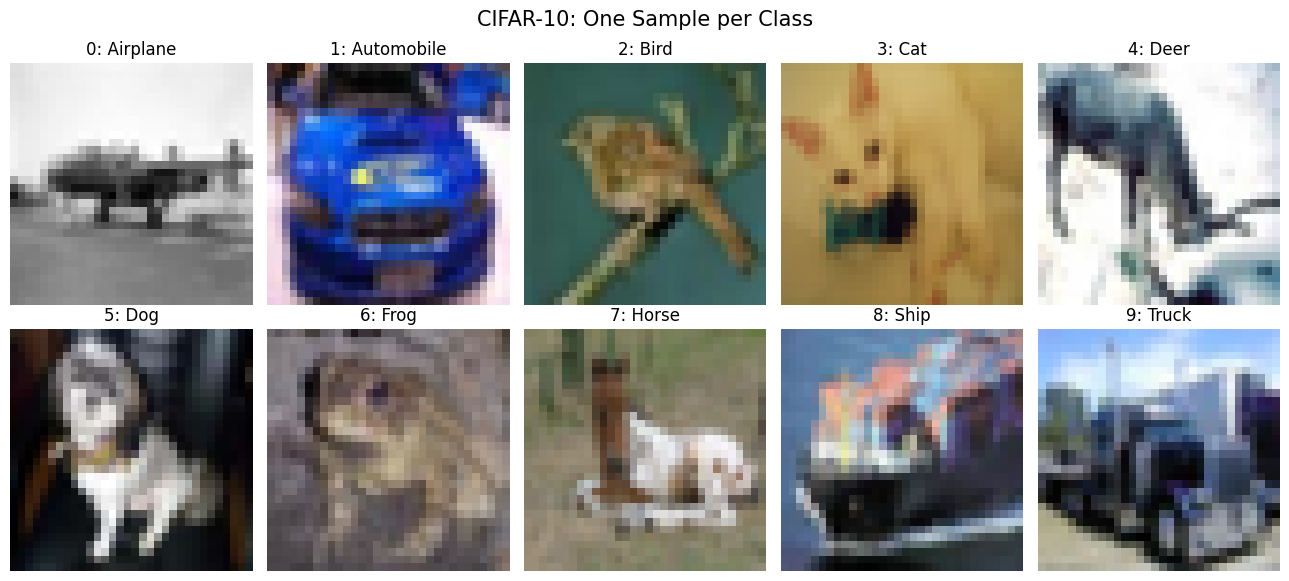

Image dimensions: (32, 32)
Image mode: RGB


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Select one image from each class
samples = (
    train_df.groupby("label")
    .sample(n=1, random_state=42)
    .sort_values("label")
)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    image = TRAIN_IMAGES[row["array_index"]]

    ax.imshow(image)
    ax.set_title(f"{row['label']}: {class_names[row['label']]}")
    ax.axis("off")

plt.suptitle("CIFAR-10: One Sample per Class", fontsize=15)
plt.tight_layout()
plt.show()

# Verify image dimensions
image = Image.open(
    DATA_DIR / "train_images" / train_df.iloc[0]["filename"]
)

print("Image dimensions:", image.size)
print("Image mode:", image.mode)

In [ ]:
from sklearn.model_selection import train_test_split

if CONFIG["validation_fraction"] > 0:
    train_data, val_data = train_test_split(
        train_df,
        test_size=CONFIG["validation_fraction"],
        random_state=CONFIG["split_seed"],
        stratify=train_df["label"]
    )
else:
    # sla_full: train on every permitted image, no holdout.
    train_data = train_df.copy()
    val_data = train_df.iloc[0:0].copy()

train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))

print("\nTraining class distribution:")
print(train_data["label"].value_counts().sort_index())

if len(val_data):
    print("\nValidation class distribution:")
    print(val_data["label"].value_counts().sort_index())

# Ensure there is no overlap
assert set(train_data["id"]).isdisjoint(set(val_data["id"]))

print("\nSplit successful! No overlapping images.")

train_data.to_csv(OUTPUT_DIR / "train_split.csv", index=False)
val_data.to_csv(OUTPUT_DIR / "validation_split.csv", index=False)

Training samples: 50000
Validation samples: 0

Training class distribution:
label
0    5000
1    5000
2    5000
3    5000
4    5000
5    5000
6    5000
7    5000
8    5000
9    5000
Name: count, dtype: int64

Split successful! No overlapping images.


In [ ]:
import torch
from torchvision import transforms
from torchvision.transforms import InterpolationMode

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

train_operations = [
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(p=0.5),
]
if CONFIG["trivialaugment"]:
    # TrivialAugment: one random operation with a random strength per image (no tuning needed).
    train_operations.append(transforms.TrivialAugmentWide(
        interpolation=InterpolationMode.BILINEAR))
train_operations.extend([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
if CONFIG["cutout_size"] > 0:
    # Cutout: always erase one size x size square (RandomErasing with fixed area and square ratio).
    cutout_area = CONFIG["cutout_size"] ** 2 / (32 * 32)
    train_operations.append(transforms.RandomErasing(
        p=1.0, scale=(cutout_area, cutout_area), ratio=(1.0, 1.0), value=0))
train_transform = transforms.Compose(train_operations)
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
print("Training transformations:", train_transform)
print("Validation transformations:", val_transform)

Training transformations: Compose(
    RandomCrop(size=(32, 32), padding=4)
    RandomHorizontalFlip(p=0.5)
    TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.BILINEAR, fill=None)
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
    RandomErasing(p=1.0, scale=(0.140625, 0.140625), ratio=(1.0, 1.0), value=0, inplace=False)
)
Validation transformations: Compose(
    ToTensor()
    Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.247, 0.2435, 0.2616))
)


In [ ]:
import os
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch

class CIFAR10CustomDataset(Dataset):
    def __init__(self, dataframe, image_array, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_array = image_array
        self.array_indices = self.dataframe["array_index"].to_numpy()
        self.labels = self.dataframe["label"].to_numpy()
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        # Images come from RAM (TRAIN_IMAGES), not from disk.
        image = Image.fromarray(self.image_array[self.array_indices[idx]])

        label = int(self.labels[idx])

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = CIFAR10CustomDataset(
    train_data,
    TRAIN_IMAGES,
    train_transform
)

val_dataset = CIFAR10CustomDataset(
    val_data,
    TRAIN_IMAGES,
    val_transform
)

BATCH_SIZE = CONFIG["batch_size"]
NUM_WORKERS = min(CONFIG["num_workers"], os.cpu_count() or 1)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=NUM_WORKERS,
    persistent_workers=NUM_WORKERS > 0,
    timeout=CONFIG["loader_timeout_seconds"] if NUM_WORKERS > 0 else 0,  # try 5: fail fast instead of hanging
    worker_init_fn=seed_worker,
    generator=loader_generator,
    pin_memory=True
)

if len(val_dataset):
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        persistent_workers=NUM_WORKERS > 0,
        worker_init_fn=seed_worker,
        pin_memory=True
    )
else:
    val_loader = None  # sla_full has no validation split.

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader) if val_loader is not None else 0)
print("DataLoader workers:", NUM_WORKERS)

# Test one batch
images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label range:", labels.min().item(), "to", labels.max().item())

assert images.shape == (BATCH_SIZE, 3, 32, 32)
assert labels.min() >= 0 and labels.max() <= 9

print("\nDataLoader verification successful!")

Training images: 50000
Validation images: 0
Training batches: 195
Validation batches: 0
DataLoader workers: 4

Batch image shape: torch.Size([256, 3, 32, 32])
Batch label shape: torch.Size([256])
Image data type: torch.float32
Label range: 0 to 9

DataLoader verification successful!


In [ ]:
import torch
import torch.nn as nn

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Match dimensions when channels or resolution change
        self.shortcut = nn.Identity()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        out = self.relu(out)

        return out


# Verify the block
block = ResidualBlock(32, 64, stride=2)

test_input = torch.randn(4, 32, 32, 32)

test_output = block(test_input)

print("Input shape:", test_input.shape)
print("Output shape:", test_output.shape)

assert test_output.shape == (4, 64, 16, 16)

print("\nResidual block verification successful!")

Input shape: torch.Size([4, 32, 32, 32])
Output shape: torch.Size([4, 64, 16, 16])

Residual block verification successful!


In [ ]:
import torch
import torch.nn as nn

class CustomResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.in_channels = CONFIG["stem_channels"]

        # Initial convolution for 32x32 CIFAR images
        self.stem = nn.Sequential(
            nn.Conv2d(
                3, CONFIG["stem_channels"], kernel_size=3,
                stride=1, padding=1, bias=False
            ),
            nn.BatchNorm2d(CONFIG["stem_channels"]),
            nn.ReLU(inplace=True)
        )

        # Residual stages
        self.layer1 = self._make_layer(CONFIG["channels"][0], blocks=CONFIG["blocks"][0], stride=1)
        self.layer2 = self._make_layer(CONFIG["channels"][1], blocks=CONFIG["blocks"][1], stride=2)
        self.layer3 = self._make_layer(CONFIG["channels"][2], blocks=CONFIG["blocks"][2], stride=2)

        # Classification head
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(CONFIG["channels"][2], num_classes)

        # SLA joint head: one output per (class, rotation) pair, joint label = 4 * class + rotation.
        # Only about 10k parameters; it is also used at prediction time (rotation aggregate).
        self.joint_fc = nn.Linear(CONFIG["channels"][2], num_classes * 4)

        # He initialization for convolutions (standard for ReLU ResNets)
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")

    def _make_layer(self, out_channels, blocks, stride):
        layers = [
            ResidualBlock(
                self.in_channels, out_channels, stride
            )
        ]

        self.in_channels = out_channels

        for _ in range(1, blocks):
            layers.append(
                ResidualBlock(out_channels, out_channels)
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)

        # Returns (normal 10-class logits, 40-way joint class x rotation logits)
        return self.fc(x), self.joint_fc(x)


# Create model
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CustomResNet(num_classes=10).to(device)
model = model.to(memory_format=torch.channels_last)  # faster convolutions on T4 tensor cores

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Device:", device)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Parameter limit: {5_000_000:,}")

assert total_params <= 5_000_000, \
    "Model exceeds the parameter limit!"

# Use both GPUs when Kaggle's "GPU T4 x2" accelerator is selected.
NUM_GPUS = torch.cuda.device_count()
if NUM_GPUS > 1:
    model = nn.DataParallel(model)
print("GPUs used for training:", max(NUM_GPUS, 1))

def unwrap(network):
    """The underlying CustomResNet (needed for saving/loading when DataParallel is used)."""
    return network.module if isinstance(network, nn.DataParallel) else network

# Verify architecture using a sample batch
test_input = torch.randn(4, 3, 32, 32).to(device)

model.eval()
with torch.no_grad():
    test_output, test_joint_output = model(test_input)

print("\nInput shape:", test_input.shape)
print("Output shape:", test_output.shape)
print("Joint output shape:", test_joint_output.shape)

assert test_output.shape == (4, 10), \
    "Incorrect model output shape!"
assert test_joint_output.shape == (4, 40), \
    "Incorrect joint output shape!"

print("\nCustom ResNet verification successful!")

# try 4: frozen teacher models (try 2 and try 3) from the attached inputs. Used only during training.
TEACHERS = []
if CONFIG["kd"]:
    import glob
    teacher_paths = sorted(glob.glob(f"{INPUT_ROOT}/**/final_resnet.pth", recursive=True))
    print("\nTeacher checkpoints found:")
    for path in teacher_paths:
        print("  ", path)
    assert len(teacher_paths) == CONFIG["teacher_count"], (
        f"Expected {CONFIG['teacher_count']} teacher checkpoints, found {len(teacher_paths)}. "
        "kd3_full needs exactly: Datasets -> try2-weights, Datasets -> try4-weights, Your Work -> viral_try3 "
        "(and NOT viral_try4)."
    )
    for path in teacher_paths:
        checkpoint = torch.load(path, map_location=device, weights_only=True)
        teacher_config = checkpoint["config"]
        for key in ["blocks", "channels", "stem_channels"]:
            assert teacher_config[key] == CONFIG[key], f"Teacher {path} has a different {key}."
        assert checkpoint["epoch"] == teacher_config["epochs"], f"Teacher {path} did not finish training."
        teacher = CustomResNet(num_classes=10).to(device).to(memory_format=torch.channels_last)
        teacher.load_state_dict(checkpoint["model_state_dict"])  # raw weights (the submitted ones)
        teacher.eval()
        for parameter in teacher.parameters():
            parameter.requires_grad_(False)
        print(f"  loaded: preset={teacher_config['preset']}, kd={teacher_config.get('kd', False)}, epoch={checkpoint['epoch']}, "
              f"parameters={sum(p.numel() for p in teacher.parameters()):,}")
        if NUM_GPUS > 1:
            teacher = nn.DataParallel(teacher)
        TEACHERS.append(teacher)
    print("Teachers loaded:", len(TEACHERS), "(frozen, not part of the submitted model)")

Device: cuda
Total parameters: 4,707,442
Trainable parameters: 4,707,442
Parameter limit: 5,000,000
GPUs used for training: 1

Input shape: torch.Size([4, 3, 32, 32])
Output shape: torch.Size([4, 10])
Joint output shape: torch.Size([4, 40])

Custom ResNet verification successful!

Teacher checkpoints found:
   /content/kaggle_input/datasets/viral0401/try2-weights/final_resnet.pth
   /content/kaggle_input/datasets/viral0401/try4-weights/final_resnet.pth
   /content/kaggle_input/drive/try5/final_resnet.pth
   /content/kaggle_input/notebooks/viral0401/viral-try3/sla_full_e200_ema_seed42/checkpoints/final_resnet.pth
  loaded: preset=sla_val, kd=False, epoch=200, parameters=4,707,442
  loaded: preset=kd_full, kd=True, epoch=200, parameters=4,707,442
  loaded: preset=kd3_full, kd=True, epoch=180, parameters=4,707,442
  loaded: preset=sla_full, kd=False, epoch=200, parameters=4,707,442
Teachers loaded: 4 (frozen, not part of the submitted model)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import math

EPOCHS = CONFIG["epochs"]
LEARNING_RATE = CONFIG["learning_rate"]
WEIGHT_DECAY = CONFIG["weight_decay"]
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])

# Weight decay on conv/linear weights only; BatchNorm parameters and biases are not decayed.
decay_parameters = [p for p in model.parameters() if p.ndim > 1]
no_decay_parameters = [p for p in model.parameters() if p.ndim <= 1]
optimizer = optim.SGD([
        dict(params=decay_parameters, weight_decay=WEIGHT_DECAY),
        dict(params=no_decay_parameters, weight_decay=0.0)],
    lr=LEARNING_RATE, momentum=CONFIG["momentum"], nesterov=True)

def learning_rate_multiplier(epoch):
    warmup = CONFIG["warmup_epochs"]
    if epoch < warmup:
        return (epoch + 1) / warmup
    progress = min(1.0, max(0.0, (epoch - warmup) / max(1, EPOCHS - warmup - 1)))
    floor = CONFIG["minimum_lr"] / LEARNING_RATE
    return floor + (1.0 - floor) * (1.0 + math.cos(math.pi * progress)) / 2.0

scheduler = optim.lr_scheduler.LambdaLR(optimizer, learning_rate_multiplier)

# try 3: exponential moving average (EMA) of the weights AND the BatchNorm running statistics.
# After every optimizer step: ema = 0.999 * ema + 0.001 * current weights.
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
ema_model = AveragedModel(unwrap(model), multi_avg_fn=get_ema_multi_avg_fn(CONFIG["ema_decay"]),
                          use_buffers=True)

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = CHECKPOINT_DIR / "best_resnet.pth"
LATEST_MODEL_PATH = CHECKPOINT_DIR / "latest_resnet.pth"
FINAL_MODEL_PATH = CHECKPOINT_DIR / "final_resnet.pth"
history = {key: [] for key in ["train_loss", "train_acc", "val_loss", "val_acc", "learning_rate", "epoch_seconds",
                               "ema_val_loss", "ema_val_acc"]}
best_val_acc = 0.0
print("Epochs:", EPOCHS, "| batch size:", BATCH_SIZE, "| peak lr:", LEARNING_RATE)
print("Optimizer:", type(optimizer).__name__, "| scheduler:", type(scheduler).__name__)
print("Decayed tensors:", len(decay_parameters), "| non-decayed tensors:", len(no_decay_parameters))
print("Final checkpoint:", FINAL_MODEL_PATH)
print("Last-epoch lr:", LEARNING_RATE * learning_rate_multiplier(EPOCHS - 1))
print("EMA decay:", CONFIG["ema_decay"], "| EMA tensors tracked:",
      sum(1 for _ in ema_model.module.parameters()) + sum(1 for _ in ema_model.module.buffers()))

Epochs: 200 | batch size: 256 | peak lr: 0.2
Optimizer: SGD | scheduler: LambdaLR
Decayed tensors: 27 | non-decayed tensors: 52
Final checkpoint: /kaggle/working/kd4_full_e200_ema_seed42/checkpoints/final_resnet.pth
Last-epoch lr: 0.0001
EMA decay: 0.999 | EMA tensors tracked: 154


In [ ]:
from tqdm.auto import tqdm
import torch
import torch.nn.functional as F

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

def rotate_four_ways(images):
    """Stack the 4 rotations of every image: row 4*i + k is image i rotated by k*90 degrees."""
    rotated = torch.stack([torch.rot90(images, k, dims=(2, 3)) for k in range(4)], dim=1)
    return rotated.reshape(-1, *images.shape[1:]).contiguous(memory_format=torch.channels_last)

def rotation_aggregate(joint_logits, batch_size):
    """SLA aggregation: for the copy rotated by k keep the logits of (class, k), then average over k."""
    grouped = joint_logits.float().view(batch_size, 4, -1)
    return torch.stack([grouped[:, k, k::4] for k in range(4)]).mean(0)

def sla_loss(logits, joint_logits, labels, criterion):
    """SLA+SD loss (Lee et al., 2020):
    joint CE over (class, rotation) labels + KL(aggregate -> normal head) + CE of the normal head."""
    batch_size = labels.size(0)
    rotations = torch.arange(4, device=labels.device)
    joint_labels = (labels.view(-1, 1) * 4 + rotations.view(1, -1)).reshape(-1)
    joint_loss = F.cross_entropy(joint_logits.float(), joint_labels)
    plain_logits = logits[::4].float()  # normal head on the unrotated copy
    aggregated = rotation_aggregate(joint_logits, batch_size).detach()
    distill_loss = F.kl_div(F.log_softmax(plain_logits, dim=1), F.softmax(aggregated, dim=1),
                            reduction="batchmean")
    plain_loss = criterion(plain_logits, labels)
    loss = joint_loss + CONFIG["sd_weight"] * distill_loss + CONFIG["plain_ce_weight"] * plain_loss
    return loss, plain_logits

@torch.no_grad()
def teacher_probabilities(images):
    """Average of the teachers' softened probabilities (temperature T) on the same augmented images."""
    temperature = CONFIG["kd_temperature"]
    views = [images, torch.flip(images, dims=[3])] if CONFIG.get("teacher_flip", False) else [images]
    probabilities = 0
    for teacher in TEACHERS:
        for view in views:
            with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                teacher_logits, _ = teacher(view)
            probabilities = probabilities + F.softmax(teacher_logits.float() / temperature, dim=1)
    return probabilities / (len(TEACHERS) * len(views))

def distillation_loss(student_logits, soft_targets):
    """Hinton et al. (2015): KL(teacher || student) at temperature T, scaled by T^2."""
    temperature = CONFIG["kd_temperature"]
    return F.kl_div(F.log_softmax(student_logits / temperature, dim=1), soft_targets,
                    reduction="batchmean") * temperature ** 2

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = correct = total = 0
    progress = tqdm(loader, desc="Training", leave=False)
    for images, labels in progress:
        images = images.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        soft_targets = teacher_probabilities(images) if CONFIG["kd"] else None
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            if CONFIG["sla"]:
                logits, joint_logits = model(rotate_four_ways(images))
            else:
                logits, joint_logits = model(images)
        if CONFIG["sla"]:
            loss, outputs = sla_loss(logits, joint_logits, labels, criterion)
        else:
            outputs = logits.float()
            loss = criterion(outputs, labels)
        if CONFIG["kd"]:
            # try 4: the normal head (unrotated images) also matches the teachers' soft predictions.
            loss = loss + CONFIG["kd_weight"] * distillation_loss(outputs, soft_targets)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        ema_model.update_parameters(unwrap(model))  # try 3: update the weight average every step
        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
        progress.set_postfix(loss=f"{running_loss / total:.4f}", acc=f"{100 * correct / total:.2f}%")
    return running_loss / total, 100 * correct / total

@torch.no_grad()
def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = correct = total = 0
    for images, labels in tqdm(loader, desc="Validation", leave=False):
        images = images.to(device, non_blocking=True).contiguous(memory_format=torch.channels_last)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            outputs, _ = model(images)
        outputs = outputs.float()
        loss = criterion(outputs, labels)
        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100 * correct / total

print("Training and validation functions ready; mixed precision:", scaler.is_enabled())
print("Rotation self-supervision (SLA+SD):", CONFIG["sla"])
print("Train accuracy is measured on the augmented, unrotated images (normal head).")
print("The EMA model is updated after every optimizer step.")
print("Knowledge distillation:", CONFIG["kd"], "| teachers:", len(TEACHERS),
      "| mirrored teacher predictions:", CONFIG.get("teacher_flip", False),
      "| temperature:", CONFIG["kd_temperature"], "| weight:", CONFIG["kd_weight"])

Training and validation functions ready; mixed precision: True
Rotation self-supervision (SLA+SD): True
Train accuracy is measured on the augmented, unrotated images (normal head).
The EMA model is updated after every optimizer step.
Knowledge distillation: True | teachers: 4 | mirrored teacher predictions: True | temperature: 4.0 | weight: 1.0


In [ ]:
import time
import torch

def capture_random_state():
    state = np.random.get_state()
    return {"python": random.getstate(), "numpy": [state[0], state[1].tolist(), state[2], state[3], state[4]],
        "torch": torch.get_rng_state(), "loader": loader_generator.get_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}

def restore_random_state(state):
    random.setstate(state["python"])
    a = state["numpy"]
    np.random.set_state((a[0], np.asarray(a[1], dtype=np.uint32), a[2], a[3], a[4]))
    torch.set_rng_state(state["torch"].cpu())
    loader_generator.set_state(state["loader"].cpu())
    if torch.cuda.is_available() and state["cuda"]:
        # The checkpoint may come from a machine with a different number of GPUs (Kaggle 2x T4 -> Colab A100).
        for index, item in enumerate(state["cuda"][:torch.cuda.device_count()]):
            torch.cuda.set_rng_state(item.cpu(), index)

def run_training(start_epoch=0, end_epoch=None):
    global best_val_acc
    stop_epoch = EPOCHS if end_epoch is None else min(end_epoch, EPOCHS)
    for epoch in range(start_epoch, stop_epoch):
        start_time = time.time()
        print(f"\nEpoch {epoch + 1}/{EPOCHS}")
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        if val_loader is not None:
            val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, device)
            ema_val_loss, ema_val_acc = validate_one_epoch(ema_model, val_loader, criterion, device)
        else:
            val_loss, val_acc = float("nan"), float("nan")
            ema_val_loss, ema_val_acc = float("nan"), float("nan")
        current_lr = optimizer.param_groups[0]["lr"]
        scheduler.step()
        values = [train_loss, train_acc, val_loss, val_acc, current_lr, time.time() - start_time,
                  ema_val_loss, ema_val_acc]
        for key, value in zip(history, values):
            history[key].append(value)
        if val_loader is not None and val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save({"epoch": epoch + 1, "model_state_dict": unwrap(model).state_dict(),
                "val_acc": val_acc, "train_acc": train_acc, "config": CONFIG,
                "config_signature": CONFIG_SIGNATURE, "trainable_parameters": trainable_params}, BEST_MODEL_PATH)
            print("New best model saved!")
        torch.save({"epoch": epoch + 1, "model_state_dict": unwrap(model).state_dict(),
            "optimizer_state_dict": optimizer.state_dict(), "scheduler_state_dict": scheduler.state_dict(),
            "scaler_state_dict": scaler.state_dict(), "best_val_acc": best_val_acc,
            "ema_state_dict": ema_model.state_dict(),
            "history": history, "config": CONFIG, "config_signature": CONFIG_SIGNATURE,
            "random_state": capture_random_state()}, LATEST_MODEL_PATH)
        pd.DataFrame(history).rename_axis("epoch_zero_based").to_csv(OUTPUT_DIR / "history.csv")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}% | EMA Val Acc: {ema_val_acc:.2f}%")
        print(f"LR: {current_lr:.6f} | Time: {history['epoch_seconds'][-1]:.1f}s | Best: {best_val_acc:.2f}%")
        if epoch + 1 == EPOCHS:
            # The full schedule finished: the end-of-schedule weights are the model we submit.
            torch.save({"epoch": epoch + 1, "model_state_dict": unwrap(model).state_dict(),
                "ema_state_dict": ema_model.state_dict(), "ema_val_acc": ema_val_acc,
                "val_acc": val_acc, "train_acc": train_acc, "config": CONFIG,
                "config_signature": CONFIG_SIGNATURE, "trainable_parameters": trainable_params}, FINAL_MODEL_PATH)
            print("Final model saved:", FINAL_MODEL_PATH)
    print("Completed epochs:", len(history["val_acc"]))

print("Main training loop configured.")

Main training loop configured.


In [ ]:
# Keep the original one-epoch smoke test, but do not reset the full schedule.
# It also projects the full run time so we never get cut off mid-schedule again (improved_v1 stopped at 161/200).
start_epoch = 0
if not RESUME_FROM:
    assert not LATEST_MODEL_PATH.exists(), (
        "This RUN_NAME already has a checkpoint. Set RESUME_FROM to it, or use a new RUN_NAME."
    )
    run_training(start_epoch=0, end_epoch=1)
    start_epoch = 1
    first_epoch_seconds = history["epoch_seconds"][0]
    projected_hours = first_epoch_seconds * EPOCHS / 3600
    print(f"\nFirst epoch: {first_epoch_seconds:.1f}s -> projected full run: {projected_hours:.1f} hours")
    print("(Epoch 1 includes cuDNN autotuning and worker start-up, so the real total is usually a bit lower.)")
    if projected_hours > 10:
        print("NOTE: long run. Keep the tab open; if Colab disconnects, reconnect and Run all to resume.")
else:
    print("Smoke test skipped; the next cell will restore the selected checkpoint.")


Epoch 1/200


Training:   0%|          | 0/195 [00:00<?, ?it/s]

Train Loss: 8.1691 | Train Acc: 17.25%
Val Loss: nan | Val Acc: nan% | EMA Val Acc: nan%
LR: 0.040000 | Time: 26.0s | Best: 0.00%
Completed epochs: 1

First epoch: 26.0s -> projected full run: 1.4 hours
(Epoch 1 includes cuDNN autotuning and worker start-up, so the real total is usually a bit lower.)


In [ ]:
# Optional resume is restricted to this exact configuration.
if RESUME_FROM:
    resume_path = Path(RESUME_FROM)
    checkpoint = torch.load(resume_path, map_location=device, weights_only=True)
    assert checkpoint.get("config_signature") == CONFIG_SIGNATURE, (
        "Checkpoint configuration differs. Do not resume a different preset or architecture here."
    )
    unwrap(model).load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    ema_model.load_state_dict(checkpoint["ema_state_dict"])
    best_val_acc = checkpoint["best_val_acc"]
    history = checkpoint["history"]
    start_epoch = checkpoint["epoch"]
    restore_random_state(checkpoint["random_state"])
    # Preserve the earlier best checkpoint (validation presets only).
    import shutil
    sibling_best = resume_path.parent / "best_resnet.pth"
    if sibling_best.is_file() and sibling_best.resolve() != BEST_MODEL_PATH.resolve():
        shutil.copy2(sibling_best, BEST_MODEL_PATH)
    if start_epoch == EPOCHS and not FINAL_MODEL_PATH.exists():
        # The resumed run had already finished: its weights are the final model.
        torch.save({"epoch": EPOCHS, "model_state_dict": unwrap(model).state_dict(),
            "ema_state_dict": ema_model.state_dict(), "ema_val_acc": history["ema_val_acc"][-1],
            "val_acc": history["val_acc"][-1], "train_acc": history["train_acc"][-1], "config": CONFIG,
            "config_signature": CONFIG_SIGNATURE, "trainable_parameters": trainable_params}, FINAL_MODEL_PATH)
print("Completed epochs:", start_epoch)
print("Remaining epochs:", EPOCHS - start_epoch)
print("Current learning rate:", optimizer.param_groups[0]["lr"])

Completed epochs: 1
Remaining epochs: 199
Current learning rate: 0.08000000000000002


In [ ]:
# Resume training from the saved checkpoint
run_training(start_epoch=start_epoch)


Epoch 2/200


Training:   0%|          | 0/195 [00:00<?, ?it/s]

Train Loss: 7.0717 | Train Acc: 30.87%
Val Loss: nan | Val Acc: nan% | EMA Val Acc: nan%
LR: 0.080000 | Time: 18.6s | Best: 0.00%

Epoch 3/200


Training:   0%|          | 0/195 [00:00<?, ?it/s]

Train Loss: 6.3431 | Train Acc: 40.63%
Val Loss: nan | Val Acc: nan% | EMA Val Acc: nan%
LR: 0.120000 | Time: 18.7s | Best: 0.00%

Epoch 4/200


Training:   0%|          | 0/195 [00:00<?, ?it/s]

... (389 outputs left out)

Training:   0%|          | 0/195 [00:00<?, ?it/s]

Train Loss: 1.2363 | Train Acc: 93.86%
Val Loss: nan | Val Acc: nan% | EMA Val Acc: nan%
LR: 0.000113 | Time: 18.6s | Best: 0.00%

Epoch 200/200


Training:   0%|          | 0/195 [00:00<?, ?it/s]

Train Loss: 1.2251 | Train Acc: 94.02%
Val Loss: nan | Val Acc: nan% | EMA Val Acc: nan%
LR: 0.000100 | Time: 18.7s | Best: 0.00%
Final model saved: /kaggle/working/kd4_full_e200_ema_seed42/checkpoints/final_resnet.pth
Completed epochs: 200


In [ ]:
import torch
import torch.nn.functional as F

# Use the END-of-schedule weights (not the best-validation epoch): with cosine-to-zero they are the
# converged model, and it avoids choosing a checkpoint by peeking at validation many times.
assert FINAL_MODEL_PATH.is_file(), "Training has not finished all epochs yet; resume it before predicting."
final_checkpoint = torch.load(FINAL_MODEL_PATH, map_location=device, weights_only=True)
assert final_checkpoint["config_signature"] == CONFIG_SIGNATURE
assert final_checkpoint["epoch"] == EPOCHS
unwrap(model).load_state_dict(final_checkpoint["model_state_dict"])
ema_model.load_state_dict(final_checkpoint["ema_state_dict"])
model.eval()
ema_model.eval()
print("Final checkpoint epoch:", final_checkpoint["epoch"])

# try 3: two candidate weight sets from the same run.
MODELS = {"raw": model, "ema": ema_model}

# name -> (horizontal flip, 1-pixel shifts, rotation aggregate)
INFERENCE_MODES = {
    "plain": (False, False, False),
    "flip": (True, False, False),
    "flip_shift": (True, True, False),
    "flip_shift_agg": (True, True, True),
}
candidate_modes = list(INFERENCE_MODES) if CONFIG["sla"] else ["plain", "flip", "flip_shift"]
SHIFTS = [(1, 0), (-1, 0), (0, 1), (0, -1)]

def make_views(images, use_flip, use_shift):
    views = [images]
    if use_shift:
        padded = F.pad(images, (1, 1, 1, 1), mode="reflect")
        for dy, dx in SHIFTS:
            views.append(padded[:, :, 1 + dy:33 + dy, 1 + dx:33 + dx])
    if use_flip:
        views = views + [torch.flip(view, dims=[3]) for view in views]
    return [view.contiguous(memory_format=torch.channels_last) for view in views]

@torch.inference_mode()
def predict_probabilities(model, images, mode):
    use_flip, use_shift, use_aggregate = INFERENCE_MODES[mode]
    images = images.to(device, non_blocking=True)
    views = make_views(images, use_flip, use_shift)
    head_probabilities = 0
    aggregate_probabilities = 0
    for view in views:
        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            if use_aggregate:
                logits, joint_logits = model(rotate_four_ways(view))
                logits = logits[::4]
            else:
                logits, _ = model(view)
        head_probabilities = head_probabilities + logits.float().softmax(dim=1)
        if use_aggregate:
            aggregate_probabilities = aggregate_probabilities + rotation_aggregate(joint_logits, len(view)).softmax(dim=1)
    probabilities = head_probabilities / len(views)
    if use_aggregate:
        probabilities = (probabilities + aggregate_probabilities / len(views)) / 2
    return probabilities

# Select (weights, inference mode) using validation labels only; ties keep raw weights and the simpler mode.
candidates = [(weights, mode) for weights in MODELS for mode in candidate_modes]
validation_scores = {}
if val_loader is not None:
    correct = {candidate: 0 for candidate in candidates}
    total = 0
    for images, labels in tqdm(val_loader, desc="Compare validation inference"):
        labels = labels.to(device)
        for weights, mode in candidates:
            predictions = predict_probabilities(MODELS[weights], images, mode).argmax(1)
            correct[(weights, mode)] += (predictions == labels).sum().item()
        total += labels.size(0)
    validation_scores = {f"{w}/{m}": 100 * correct[(w, m)] / total for w, m in candidates}
    print(f"{'mode':>15} | {'raw':>7} | {'EMA':>7}")
    for mode in candidate_modes:
        print(f"{mode:>15} | {validation_scores['raw/' + mode]:6.2f}% | {validation_scores['ema/' + mode]:6.2f}%")
    FINAL_WEIGHTS, INFERENCE_MODE = max(
        candidates, key=lambda c: (round(validation_scores[f"{c[0]}/{c[1]}"], 4), -candidates.index(c)))
    plain_val_acc = validation_scores["raw/plain"]
    assert abs(plain_val_acc - final_checkpoint["val_acc"]) <= 0.10, "Unexpected validation mismatch; investigate before submitting."
else:
    # sla_full has no validation split: raw weights (the proven try-2 recipe) + the mode set in the preset.
    FINAL_WEIGHTS = "raw"
    INFERENCE_MODE = "flip"
    plain_val_acc = float("nan")
if CONFIG["inference_mode"] != "auto":
    INFERENCE_MODE = CONFIG["inference_mode"]
if CONFIG["final_weights"] != "auto":
    FINAL_WEIGHTS = CONFIG["final_weights"]
OTHER_WEIGHTS = "ema" if FINAL_WEIGHTS == "raw" else "raw"
selected_val_acc = validation_scores.get(f"{FINAL_WEIGHTS}/{INFERENCE_MODE}", float("nan"))
print("Selected weights:", FINAL_WEIGHTS, "| selected inference mode:", INFERENCE_MODE)
print("These are validation scores, not hidden evaluation accuracy.")

Final checkpoint epoch: 200
Selected weights: raw | selected inference mode: flip
These are validation scores, not hidden evaluation accuracy.


In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path
import pandas as pd

TEST_DIR = DATA_DIR / "test_images"

# Use the official ID/filename manifest, not guessed filename ordering.
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_df = pd.read_csv(DATA_DIR / "sample_submission.csv")
assert test_df["id"].is_unique and sample_df["id"].is_unique
assert set(test_df["id"]) == set(sample_df["id"])
test_df = test_df.set_index("id").loc[sample_df["id"]].reset_index()
test_files = [TEST_DIR / filename for filename in test_df["filename"]]

# Row positions of these files inside TEST_IMAGES (loaded in test_manifest order).
test_position = {filename: index for index, filename in enumerate(test_manifest["filename"])}
test_indices = [test_position[filename] for filename in test_df["filename"]]

class CIFAR10TestDataset(Dataset):
    def __init__(self, image_array, indices, transform):
        self.image_array = image_array
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image = Image.fromarray(self.image_array[self.indices[idx]])

        image = self.transform(image)

        return image


test_dataset = CIFAR10TestDataset(
    TEST_IMAGES,
    test_indices,
    val_transform
)

# Avoid multiprocessing warnings during inference
test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Test images:", len(test_dataset))
print("Test batches:", len(test_loader))
print("First 5 filenames:", [p.name for p in test_files[:5]])
print("Last 5 filenames:", [p.name for p in test_files[-5:]])

# Verify one batch
test_batch = next(iter(test_loader))
print("\nTest batch shape:", test_batch.shape)

assert len(test_dataset) == 2000
assert test_batch.shape == (128, 3, 32, 32)

print("\nTest DataLoader verification successful!")

Test images: 2000
Test batches: 16
First 5 filenames: ['test_0000.png', 'test_0001.png', 'test_0002.png', 'test_0003.png', 'test_0004.png']
Last 5 filenames: ['test_1995.png', 'test_1996.png', 'test_1997.png', 'test_1998.png', 'test_1999.png']

Test batch shape: torch.Size([128, 3, 32, 32])

Test DataLoader verification successful!


In [ ]:
import torch
import numpy as np
from tqdm.auto import tqdm

model.eval()
ema_model.eval()
probabilities_by_weights = {}
for weights, network in MODELS.items():
    chunks = []
    for images in tqdm(test_loader, desc=f"Predicting evaluation images ({weights})"):
        chunks.append(predict_probabilities(network, images, INFERENCE_MODE).cpu())
    probabilities_by_weights[weights] = torch.cat(chunks).numpy()
    # Probabilities are saved so different runs can be averaged later (ensembling) without retraining.
    np.save(OUTPUT_DIR / f"test_probabilities_{weights}.npy", probabilities_by_weights[weights])
all_probabilities = probabilities_by_weights[FINAL_WEIGHTS]
np.save(OUTPUT_DIR / "test_probabilities.npy", all_probabilities)
all_predictions = all_probabilities.argmax(axis=1).tolist()
other_predictions = probabilities_by_weights[OTHER_WEIGHTS].argmax(axis=1).tolist()
assert len(all_predictions) == len(other_predictions) == len(test_df)
assert all(0 <= value <= 9 for value in all_predictions + other_predictions)
agreement = 100 * np.mean(np.array(all_predictions) == np.array(other_predictions))
print("Total predictions:", len(all_predictions))
print("Weights:", FINAL_WEIGHTS, "| inference mode:", INFERENCE_MODE)
print(f"Raw and EMA predictions agree on {agreement:.1f}% of evaluation images.")
teacher_ensemble_predictions = None
if TEACHERS:
    # Reference only: the averaged teachers are several models (4.71M parameters each).
    teacher_chunks = []
    for images in tqdm(test_loader, desc="Predicting evaluation images (teacher ensemble)"):
        teacher_chunks.append(sum(predict_probabilities(t, images, INFERENCE_MODE) for t in TEACHERS).cpu() / len(TEACHERS))
    teacher_ensemble_probabilities = torch.cat(teacher_chunks).numpy()
    np.save(OUTPUT_DIR / "test_probabilities_teacher_ensemble.npy", teacher_ensemble_probabilities)
    teacher_ensemble_predictions = teacher_ensemble_probabilities.argmax(axis=1).tolist()
    student_vs_teachers = 100 * np.mean(np.array(all_predictions) == np.array(teacher_ensemble_predictions))
    print(f"Student and teacher ensemble agree on {student_vs_teachers:.1f}% of evaluation images.")
unique, counts = np.unique(all_predictions, return_counts=True)
print("\nPredicted class distribution:")
for label, count in zip(unique, counts):
    print(f"{label} ({class_names[label]}): {count}")
print("Hidden accuracy is unknown until Kaggle scores the CSV.")

Predicting evaluation images (raw):   0%|          | 0/16 [00:00<?, ?it/s]

Predicting evaluation images (ema):   0%|          | 0/16 [00:00<?, ?it/s]

Total predictions: 2000
Weights: raw | inference mode: flip
Raw and EMA predictions agree on 99.5% of evaluation images.


Predicting evaluation images (teacher ensemble):   0%|          | 0/16 [00:00<?, ?it/s]

Student and teacher ensemble agree on 96.4% of evaluation images.

Predicted class distribution:
0 (Airplane): 183
1 (Automobile): 224
2 (Bird): 211
3 (Cat): 191
4 (Deer): 196
5 (Dog): 217
6 (Frog): 180
7 (Horse): 203
8 (Ship): 200
9 (Truck): 195
Hidden accuracy is unknown until Kaggle scores the CSV.


In [ ]:
import pandas as pd

submission_df = sample_df[["id"]].copy()
submission_df["label"] = all_predictions
assert submission_df.columns.tolist() == ["id", "label"]
assert submission_df["id"].tolist() == sample_df["id"].tolist()
assert len(submission_df) == len(test_df) == 2000
assert submission_df["id"].is_unique
assert submission_df["label"].isin(range(10)).all()
SUBMISSION_PATH = OUTPUT_DIR / "submission.csv"
submission_df.to_csv(SUBMISSION_PATH, index=False)
# Root copy is convenient in Kaggle's output picker.
submission_df.to_csv("/kaggle/working/submission.csv", index=False)
# Also write the other weight set, so raw and EMA can both be submitted and compared.
other_submission_df = sample_df[["id"]].copy()
other_submission_df["label"] = other_predictions
assert other_submission_df["label"].isin(range(10)).all() and len(other_submission_df) == 2000
OTHER_SUBMISSION_PATH = OUTPUT_DIR / f"submission_{OTHER_WEIGHTS}.csv"
other_submission_df.to_csv(OTHER_SUBMISSION_PATH, index=False)
print(submission_df.head())
print(f"Submission saved ({FINAL_WEIGHTS} weights):", SUBMISSION_PATH)
print(f"Alternative saved ({OTHER_WEIGHTS} weights):", OTHER_SUBMISSION_PATH)
if teacher_ensemble_predictions is not None:
    ensemble_df = sample_df[["id"]].copy()
    ensemble_df["label"] = teacher_ensemble_predictions
    ensemble_df.to_csv(OUTPUT_DIR / "submission_teacher_ensemble_REFERENCE_ONLY.csv", index=False)
    print(f"Teacher-ensemble reference saved ({len(TEACHERS)} models; submit only if the TA allows ensembles).")

   id  label
0   0      6
1   1      3
2   2      3
3   3      9
4   4      3
Submission saved (raw weights): /kaggle/working/kd4_full_e200_ema_seed42/submission.csv
Alternative saved (ema weights): /kaggle/working/kd4_full_e200_ema_seed42/submission_ema.csv
Teacher-ensemble reference saved (4 models; submit only if the TA allows ensembles).


In [ ]:
# Verify against the mounted sample without any API downloads.
verified_submission = pd.read_csv(SUBMISSION_PATH)
assert verified_submission.columns.tolist() == sample_df.columns.tolist() == ["id", "label"]
assert verified_submission["id"].tolist() == sample_df["id"].tolist()
assert len(verified_submission) == len(sample_df)
assert verified_submission["label"].isin(range(10)).all()
assert pd.api.types.is_integer_dtype(verified_submission["label"])
import hashlib
SUBMISSION_SHA256 = hashlib.sha256(SUBMISSION_PATH.read_bytes()).hexdigest()
print("Submission format verified. SHA256:", SUBMISSION_SHA256)

Submission format verified. SHA256: d026d967fb9b493d17a714ce6373ed2ee96aa0b1eac8accbf164ba55ece35e8f


In [ ]:
# Submission happens in the last cell only if SUBMIT_TO_KAGGLE is True.
print("SUBMIT_TO_KAGGLE:", SUBMIT_TO_KAGGLE)
print("If automatic submission is off or fails, submit /kaggle/working/submission.csv")
print(f"Alternative to compare: {OTHER_SUBMISSION_PATH}")
print("through the competition's Submit Predictions page.")
print("Team limit in the supplied rules: 5 submissions per day.")

SUBMIT_TO_KAGGLE: False
If automatic submission is off or fails, submit /kaggle/working/submission.csv
Alternative to compare: /kaggle/working/kd4_full_e200_ema_seed42/submission_ema.csv
through the competition's Submit Predictions page.
Team limit in the supplied rules: 5 submissions per day.


                             run  parameters            epochs  plain_val_percent  selected_val_percent  public_kaggle_percent                                                                              notes
      teammate_original_baseline     4310570                60              94.88                 94.88                   85.3                                                                 Baseline notebook.
              improved_v1_seed42     4679978 161/200 (cut off)              94.42                 95.14                   85.2                                           Schedule did not finish (lr still 0.01).
     sla_val_e200_seed42 (try 2)     4707442               200              97.88                 98.02                   90.9                         SLA+SD, TrivialAugment+Cutout, 45k images, flip inference.
sla_full_e200_ema_seed42 (try 3)     4707442               200                NaN                   NaN                   90.2                 Try 2 recipe + EM

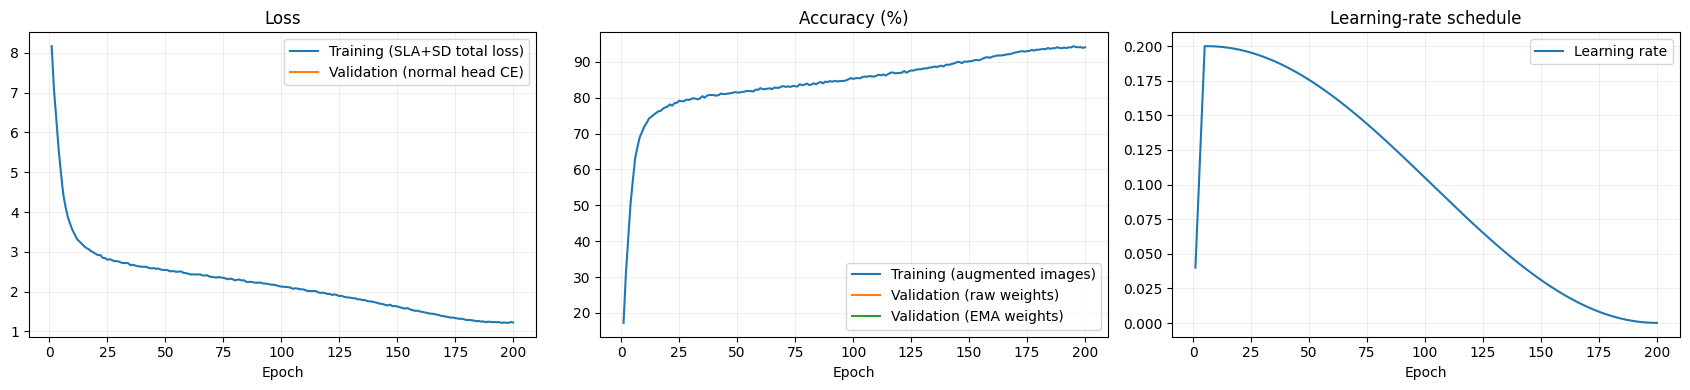

Number of trainable parameters: 4,707,442
No validation split (sla_full): the Kaggle score is the test of this run.
Saved config, changes, references, split manifests, checkpoints, history, results, comparison, and plots.
After a Kaggle submission, enter its exact percentage in PUBLIC_KAGGLE_ACCURACY_PERCENT
and rerun only this final cell to update the experiment record.


In [ ]:
# Experiment record, comparison table, and plots for the report.
import matplotlib.pyplot as plt

valid_val = [v for v in history["val_acc"] if v == v]  # drop NaN (sla_full has no validation)
best_epoch = (int(np.nanargmax(history["val_acc"])) + 1) if valid_val else None
results = {"run_name": RUN_NAME, "preset": PRESET, "config": CONFIG,
    "trainable_parameters": trainable_params, "final_epoch": final_checkpoint["epoch"],
    "best_validation_epoch": best_epoch,
    "best_validation_accuracy_percent": max(valid_val) if valid_val else None,
    "completed_epochs": len(history["val_acc"]),
    "validation_scores_by_inference_mode": validation_scores,
    "plain_validation_accuracy_percent": None if plain_val_acc != plain_val_acc else plain_val_acc,
    "selected_validation_accuracy_percent": None if selected_val_acc != selected_val_acc else selected_val_acc,
    "inference_mode": INFERENCE_MODE,
    "final_weights": FINAL_WEIGHTS,
    "ema_decay": CONFIG["ema_decay"],
    "raw_vs_ema_test_agreement_percent": float(agreement),
    "knowledge_distillation": CONFIG["kd"],
    "teacher_count": len(TEACHERS),
    "student_vs_teacher_ensemble_test_agreement_percent":
        float(student_vs_teachers) if teacher_ensemble_predictions is not None else None,
    "public_kaggle_accuracy_percent": PUBLIC_KAGGLE_ACCURACY_PERCENT,
    "private_kaggle_accuracy_percent": None,
    "submission_sha256": SUBMISSION_SHA256,
    "total_training_seconds": sum(history["epoch_seconds"]),
    "environment": ENVIRONMENT,
    "interpretation": "Raw vs EMA columns isolate weight averaging; sla_val vs no_sla_val isolates rotation self-supervision."}
(OUTPUT_DIR / "results.json").write_text(json.dumps(results, indent=2))
comparison = pd.DataFrame([
    {"run": "teammate_original_baseline", "parameters": 4310570, "epochs": 60,
     "plain_val_percent": 94.88, "selected_val_percent": 94.88, "public_kaggle_percent": 85.3,
     "notes": "Baseline notebook."},
    {"run": "improved_v1_seed42", "parameters": 4679978, "epochs": "161/200 (cut off)",
     "plain_val_percent": 94.42, "selected_val_percent": 95.14, "public_kaggle_percent": 85.2,
     "notes": "Schedule did not finish (lr still 0.01)."},
    {"run": "sla_val_e200_seed42 (try 2)", "parameters": 4707442, "epochs": 200,
     "plain_val_percent": 97.88, "selected_val_percent": 98.02, "public_kaggle_percent": 90.9,
     "notes": "SLA+SD, TrivialAugment+Cutout, 45k images, flip inference."},
    {"run": "sla_full_e200_ema_seed42 (try 3)", "parameters": 4707442, "epochs": 200,
     "plain_val_percent": None, "selected_val_percent": None, "public_kaggle_percent": 90.2,
     "notes": "Try 2 recipe + EMA on all 50k images, raw weights, flip inference."},
    {"run": "kd_full_e200_ema_seed42 (try 4)", "parameters": 4707442, "epochs": 200,
     "plain_val_percent": None, "selected_val_percent": None, "public_kaggle_percent": 91.5,
     "notes": "Distilled from try 2 + try 3 (T=4, weight 1), all 50k images, raw weights, flip."},
    {"run": "kd3_full_ema_seed42 (try 5)", "parameters": 4707442, "epochs": 180,
     "plain_val_percent": None, "selected_val_percent": None, "public_kaggle_percent": 91.0,
     "notes": "Distilled from try 2 + 3 + 4, 180 epochs (Kaggle to epoch 144, finished on Colab)."},
    {"run": RUN_NAME, "parameters": trainable_params, "epochs": final_checkpoint["epoch"],
     "plain_val_percent": results["plain_validation_accuracy_percent"],
     "selected_val_percent": results["selected_validation_accuracy_percent"],
     "public_kaggle_percent": PUBLIC_KAGGLE_ACCURACY_PERCENT,
     "notes": f"Measured in this run; weights = {FINAL_WEIGHTS}, inference = {INFERENCE_MODE}."},
])
comparison.to_csv(OUTPUT_DIR / "experiment_comparison.csv", index=False)
print(comparison.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
epochs_axis = range(1, len(history["val_acc"]) + 1)
axes[0].plot(epochs_axis, history["train_loss"], label="Training (SLA+SD total loss)" if CONFIG["sla"] else "Training")
axes[0].plot(epochs_axis, history["val_loss"], label="Validation (normal head CE)")
axes[0].set_title("Loss")
axes[1].plot(epochs_axis, history["train_acc"], label="Training (augmented images)")
axes[1].plot(epochs_axis, history["val_acc"], label="Validation (raw weights)")
axes[1].plot(epochs_axis, history["ema_val_acc"], label="Validation (EMA weights)")
axes[1].set_title("Accuracy (%)")
axes[2].plot(epochs_axis, history["learning_rate"], label="Learning rate")
axes[2].set_title("Learning-rate schedule")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_curves.png", dpi=160)
plt.show()
print(f"Number of trainable parameters: {trainable_params:,}")
if results["selected_validation_accuracy_percent"] is not None:
    print(f"Final validation accuracy ({FINAL_WEIGHTS}, {INFERENCE_MODE}): {results['selected_validation_accuracy_percent']:.2f}%")
else:
    print("No validation split (sla_full): the Kaggle score is the test of this run.")
print("Saved config, changes, references, split manifests, checkpoints, history, results, comparison, and plots.")
print("After a Kaggle submission, enter its exact percentage in PUBLIC_KAGGLE_ACCURACY_PERCENT")
print("and rerun only this final cell to update the experiment record.")

In [ ]:
import os
import sys
import subprocess
from pathlib import Path
import pandas as pd

submission_path = Path("/kaggle/working/submission.csv")
sample_path = DATA_DIR / "sample_submission.csv"

assert submission_path.is_file(), (
    "Run the prediction and CSV-saving cells first."
)

submission = pd.read_csv(submission_path)
sample = pd.read_csv(sample_path)

assert submission.columns.tolist() == ["id", "label"]
assert len(submission) == len(sample)
assert submission["id"].is_unique
assert submission["id"].tolist() == sample["id"].tolist()
assert pd.api.types.is_integer_dtype(submission["label"])
assert submission["label"].isin(range(10)).all()

if not SUBMIT_TO_KAGGLE:
    print("SUBMIT_TO_KAGGLE is False: submit /kaggle/working/submission.csv manually.")
else:
    try:
        from kaggle_secrets import UserSecretsClient

        # Install/update only the Kaggle client (needs Internet ON in the notebook settings).
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"],
            check=True,
        )

        # Pass the secret to the subprocess without printing it.
        submission_env = os.environ.copy()
        submission_env["KAGGLE_API_TOKEN"] = (
            UserSecretsClient().get_secret("KAGGLE_API_TOKEN").strip()
        )

        result = subprocess.run(
            [
                "kaggle", "competitions", "submit",
                "-c", "cifar-10-res-net-architecture-challenge-dl",
                "-f", str(submission_path),
                "-m", f"{RUN_NAME}: ResNet {trainable_params / 1e6:.2f}M, {EPOCHS} epochs, "
                      f"SLA+SD={CONFIG['sla']}, KD={CONFIG['kd']}, EMA, TrivialAugment+Cutout, weights={FINAL_WEIGHTS}, inference={INFERENCE_MODE}",
            ],
            env=submission_env,
            capture_output=True,
            text=True,
        )

        # Redact the credential if an error happens to include it.
        response = (result.stdout + "\n" + result.stderr).replace(
            submission_env["KAGGLE_API_TOKEN"], "[REDACTED]"
        )
        print(response)

        if result.returncode != 0:
            print("Submission was not confirmed. Check the response and "
                  "competition Submissions tab before retrying.")
    except Exception as error:
        # Never lose a finished run because of a submission problem.
        print("Automatic submission skipped:", type(error).__name__, str(error)[:200])
        print("Submit /kaggle/working/submission.csv manually from the Output tab.")

SUBMIT_TO_KAGGLE is False: submit /kaggle/working/submission.csv manually.
